# Reto Planta Física · Entregables 1 y 2: Investigación y Desarrollo

Diseño de algoritmos matemáticos bioinspirados · MA2015 · Grupo 201

**Integrantes**

* Elisa Jiménez Calderón · A01668464
* Sofía Becerra Pedraza · A01661775
* Cecilia Correa Gálvez · A01754061

Esta libreta acumulativa parte de la **base común** proporcionada por el docente (secciones numeradas 1–12). Las celdas marcadas con **[Equipo]** son aportaciones propias del equipo.

### Rotación de responsabilidades

| Avance | Programación | Revisión | Verificación |
| --- | --- | --- | --- |
| Investigación | Todo el equipo | Elisa & Cecilia | Sofía |
| Desarrollo | Elisa & Sofía | Cecilia | Todo el equipo |
| Final | (por asignar) | (por asignar) | (por asignar) |

### [Equipo] Registro de cambios

| Avance | Cambio | Motivo |
| --- | --- | --- |
| Investigación (corrección) | Sustituciones $D_i\cdot x_i$ y comprobaciones $T_i+P_i=D_i$, $T+P=Q$ | Retroalimentación A2 |
| Investigación (corrección) | $F$ del plan máximo redondeado a 1.2512 | Retroalimentación A2 |
| Investigación (corrección) | Columna *Mes* en la tabla de demandas; fotos reducidas | Recomendaciones |
| Desarrollo | Nuevo operador de mutación `mutate_uniform_reset` (reinicio aleatorio uniforme), comparado con `mutate` de la base | Modificación sustantiva de un operador (B1) |
| Desarrollo | `run_genetic_algorithm`: ciclo del equipo que recibe el operador de mutación, guarda la historia y comprueba población, dominios y élite en cada generación | Evidencia de B1 |
| Desarrollo | Repetición con la misma semilla y entorno explícito | Reproducción (B2) |

## 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## Formulación y supuestos

### Caso
Planta Física del Campus Ciudad de México debe decidir, para **un mes** (marzo de 2025), qué parte de la demanda de agua de cuatro edificios se cubre con **agua tratada**; el resto se cubre con **agua potable**. Buscamos usar la menor cantidad posible de agua potable sin exceder la capacidad de agua tratada.

### Cromosoma, genes y decisión que representa cada gen
Un candidato es el **cromosoma** $k=(k_1,k_2,k_3,k_4)$, con **cuatro genes enteros** en el orden fijo de la tabla. Cada gen $k_i$ es un nivel discreto y su fracción es $x_i = k_i/10$ (adimensional; $100x_i$ es el porcentaje).

| Gen | Edificio | Dominio | Fracción | Decisión que representa |
| --- | --- | --- | --- | --- |
| $k_1$ | Aulas 1 | $\{0,\ldots,8\}$ | $x_1\le 0.8$ | Qué fracción de la demanda mensual de Aulas 1 se abastece con agua tratada |
| $k_2$ | Biblioteca | $\{0,\ldots,8\}$ | $x_2\le 0.8$ | Qué fracción de la demanda mensual de Biblioteca se abastece con agua tratada |
| $k_3$ | Cedetec | $\{0,\ldots,6\}$ | $x_3\le 0.6$ | Qué fracción de la demanda mensual de Cedetec se abastece con agua tratada |
| $k_4$ | Aulas 2 | $\{0,\ldots,8\}$ | $x_4\le 0.8$ | Qué fracción de la demanda mensual de Aulas 2 se abastece con agua tratada |

Por ejemplo, $k_3=6$ significa que 60 % de la demanda de Cedetec se cubre con agua tratada y el 40 % restante con agua potable. Hay $9\times9\times7\times9=5103$ cromosomas posibles. Una codificación fuera de estos dominios o no entera se **rechaza** (no se redondea ni se corrige).

### Datos observados (consumos reales)

| Edificio | Mes | Demanda $D_i$ (m³) |
| --- | --- | --- |
| Aulas 1 | marzo 2025 | 847.00 |
| Biblioteca | marzo 2025 | 462.00 |
| Cedetec | marzo 2025 | 284.21 |
| Aulas 2 | marzo 2025 | 683.00 |
| **Total** $Q=\sum_i D_i$ | marzo 2025 | **2276.21** |

Son las demandas agregadas reales de **marzo de 2025** tomadas de `consumo_agua_2023_2026.csv` (repositorio técnico MA2015-Planta-Física). Los cuatro registros no tienen banderas de imputación, cero ni anomalía. La metadata de esta libreta conserva los registros y los hashes de procedencia de las fuentes.

### Supuestos didácticos
* **Capacidad** $C = 1410$ m³/mes de agua tratada, tomada de `parametros_reto.csv` y calibrada por el docente; **no** es una capacidad confirmada por el socio.
* **Límites por edificio** (80 %, 80 %, 60 %, 80 %): definen los dominios de los genes y también son didácticos.
* El horizonte es **mensual** y las demandas son agregadas; el modelo no representa variación diaria, presiones, calidad del agua ni operación real. Los resultados describen un modelo académico, no una solución hidráulica o sanitaria validada.
* Tolerancia numérica de $10^{-8}$ m³ al comparar con la capacidad.

### Problema de optimización
Volúmenes (todos en m³ por mes):

$$T_i = D_i\,\frac{k_i}{10},\qquad T=\sum_{i=1}^{4} T_i,\qquad P = Q - T,\qquad E=\max(0,\;T-C).$$

$$\min_{k}\; P \quad \text{sujeto a}\quad k_1,k_2,k_4\in\{0,\ldots,8\},\; k_3\in\{0,\ldots,6\},\quad T\le C\;(+10^{-8}).$$

Los **dominios** limitan cada edificio por separado; la **capacidad** limita la suma de los cuatro. Los operadores conservan los dominios y el evaluador distingue la capacidad.

### Aptitud (adimensional, menor es mejor)

$$F(k)=\begin{cases}\dfrac{P}{Q}, & T\le C+10^{-8}\ \text{(factible)}\\[2mm] 1+\dfrac{E}{C}, & T> C+10^{-8}\ \text{(infactible)}\end{cases}$$

Un candidato factible tiene $F\le 1$ y uno infactible $F>1$, por lo que todo plan factible queda por delante de cualquier infactible. Entre factibles, menos agua potable implica menor $F$.

## 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

## [Equipo] Manual

Calculamos a mano dos candidatos: el reúso uniforme de 60 % y el plan con todos los genes en su máximo. Las fotografías muestran el procedimiento escrito; las tablas resumen la aritmética.

### Candidato 1: $k=(6,6,6,6)$

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) |
| --- | --- | --- | --- | --- | --- |
| Aulas 1 | 847.00 | 6 | 0.6 | 508.200 | 338.800 |
| Biblioteca | 462.00 | 6 | 0.6 | 277.200 | 184.800 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 6 | 0.6 | 409.800 | 273.200 |
| **Total** | **2276.21** | | | **T = 1365.726** | **P = 910.484** |


**Sustituciones** ($T_i=D_i\,x_i$, $P_i=D_i-T_i$ y comprobación $T_i+P_i=D_i$, en m³):

* Aulas 1: $T_1 = 847.00\times0.6 = 508.200$; $P_1 = 847.00-508.200 = 338.800$; $\;508.200+338.800 = 847.00$ ✓
* Biblioteca: $T_2 = 462.00\times0.6 = 277.200$; $P_2 = 462.00-277.200 = 184.800$; $\;277.200+184.800 = 462.00$ ✓
* Cedetec: $T_3 = 284.21\times0.6 = 170.526$; $P_3 = 284.21-170.526 = 113.684$; $\;170.526+113.684 = 284.21$ ✓
* Aulas 2: $T_4 = 683.00\times0.6 = 409.800$; $P_4 = 683.00-409.800 = 273.200$; $\;409.800+273.200 = 683.00$ ✓

**Comprobación global:** $T+P = 1365.726+910.484 = 2276.21 = Q$ ✓

* $T = 508.2+277.2+170.526+409.8 = 1365.726$ m³ $= 0.6\times2276.21$.
* $P = 2276.21-1365.726 = 910.484$ m³.
* $T=1365.726\le C=1410$: **factible**, con un margen de $1410-1365.726=44.274$ m³ sin usar. Por eso $E=\max(0,\,-44.274)=0$ m³.
* $F = P/Q = 910.484/2276.21 = 0.4$ (adimensional): 40 % de la demanda total sigue cubriéndose con agua potable.

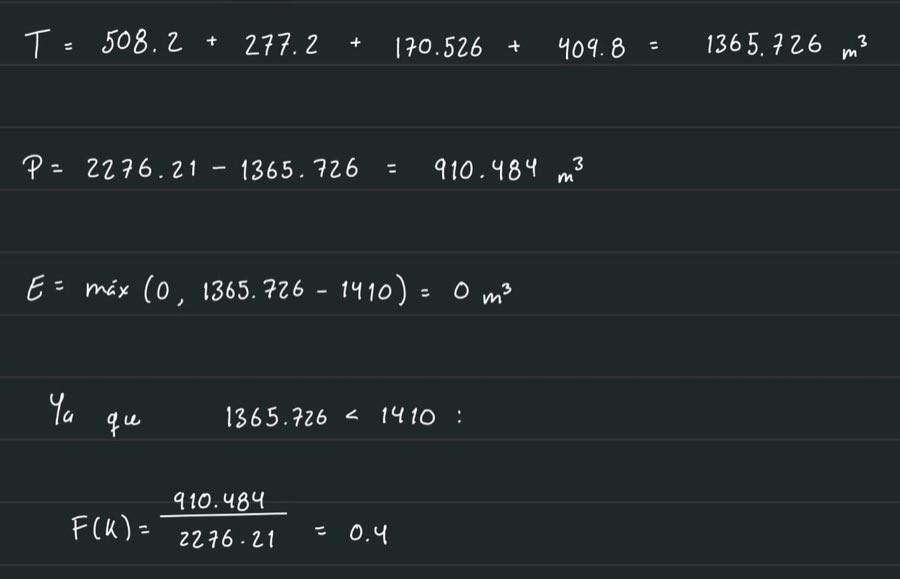

### Candidato 2 (plan máximo): $k=(8,8,6,8)$

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=D_i x_i$ (m³) | $P_i=D_i-T_i$ (m³) |
| --- | --- | --- | --- | --- | --- |
| Aulas 1 | 847.00 | 8 | 0.8 | 677.600 | 169.400 |
| Biblioteca | 462.00 | 8 | 0.8 | 369.600 | 92.400 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 8 | 0.8 | 546.400 | 136.600 |
| **Total** | **2276.21** | | | **T = 1764.126** | **P = 512.084** |


**Sustituciones** ($T_i=D_i\,x_i$, $P_i=D_i-T_i$ y comprobación $T_i+P_i=D_i$, en m³):

* Aulas 1: $T_1 = 847.00\times0.8 = 677.600$; $P_1 = 847.00-677.600 = 169.400$; $\;677.600+169.400 = 847.00$ ✓
* Biblioteca: $T_2 = 462.00\times0.8 = 369.600$; $P_2 = 462.00-369.600 = 92.400$; $\;369.600+92.400 = 462.00$ ✓
* Cedetec: $T_3 = 284.21\times0.6 = 170.526$; $P_3 = 284.21-170.526 = 113.684$; $\;170.526+113.684 = 284.21$ ✓
* Aulas 2: $T_4 = 683.00\times0.8 = 546.400$; $P_4 = 683.00-546.400 = 136.600$; $\;546.400+136.600 = 683.00$ ✓

**Comprobación global:** $T+P = 1764.126+512.084 = 2276.21 = Q$ ✓

* $T = 677.6+369.6+170.526+546.4 = 1764.126$ m³ $> C=1410$ m³: **infactible**.
* $E = 1764.126-1410 = 354.126$ m³.
* $F = 1 + E/C = 1 + 354.126/1410 = 1.251153\ldots \approx 1.2512 > 1$ (redondeado a cuatro decimales).

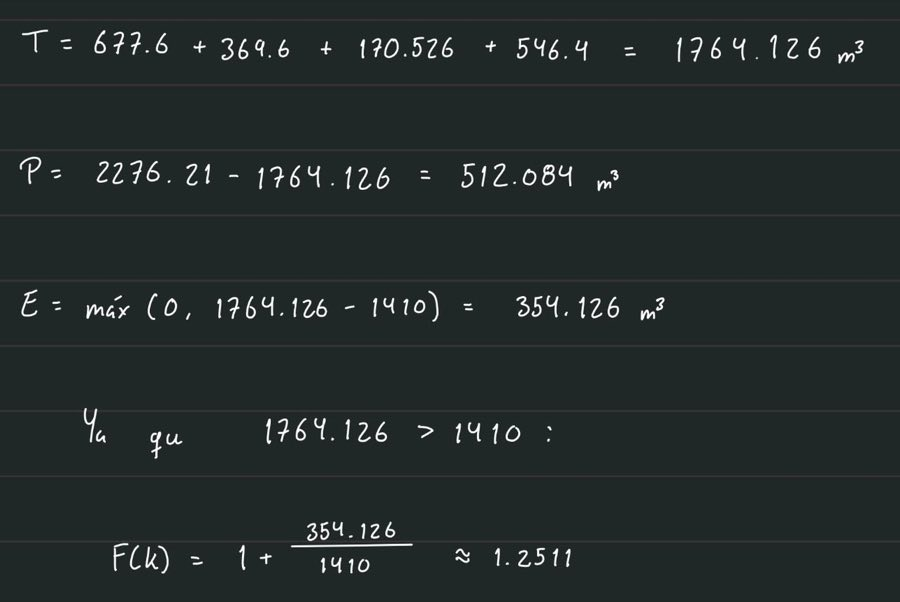

## [Equipo] Comprobación con el evaluador

Usamos `evaluate` de la base común (sección 2) para contrastar los valores calculados a mano.

In [4]:
resultado = evaluate(np.array([6, 6, 6, 6]))
manual_6 = dict(treated=1365.726, potable=910.484, excess=0.0, fitness=0.4, feasible=True)
nombres = dict(treated="T (m³)", potable="P (m³)", excess="E (m³)", fitness="F")

print(f"{'Métrica':<10}{'Manual':>12}{'evaluate':>22}{'Diferencia':>12}")
for clave, nombre in nombres.items():
    dif = resultado[clave] - manual_6[clave]
    print(f"{nombre:<10}{manual_6[clave]:>12.3f}{resultado[clave]:>22.13f}{dif:>12.1e}")
print(f"{'Factible':<10}{str(manual_6['feasible']):>12}{str(resultado['feasible']):>22}",
      "coinciden" if manual_6["feasible"] == resultado["feasible"] else "NO coinciden")

Métrica         Manual              evaluate  Diferencia
T (m³)        1365.726    1365.7259999999999    -2.3e-13
P (m³)         910.484     910.4840000000002     1.1e-13
E (m³)           0.000       0.0000000000000     0.0e+00
F                0.400       0.4000000000000     5.6e-17
Factible          True                  True coinciden


In [5]:
manual = {
    (6, 6, 6, 6): dict(treated=1365.726, potable=910.484, excess=0.0,
                       feasible=True, fitness=910.484 / 2276.21),
    (8, 8, 6, 8): dict(treated=1764.126, potable=512.084, excess=354.126,
                       feasible=False, fitness=1 + 354.126 / 1410),
}

for genes, esperado in manual.items():
    k = np.array(genes)
    r = evaluate(k)
    print(genes, "T_i (m³) =", DEMAND * k / 10)
    print({clave: (round(v, 4) if isinstance(v, float) else v) for clave, v in r.items()})
    for clave, valor in esperado.items():
        assert np.isclose(r[clave], valor), clave

print("El cálculo manual coincide con evaluate.")

(6, 6, 6, 6) T_i (m³) = [508.2   277.2   170.526 409.8  ]
{'treated': 1365.726, 'potable': 910.484, 'excess': 0.0, 'feasible': True, 'fitness': 0.4}
(8, 8, 6, 8) T_i (m³) = [677.6   369.6   170.526 546.4  ]
{'treated': 1764.126, 'potable': 512.084, 'excess': 354.126, 'feasible': False, 'fitness': 1.2512}
El cálculo manual coincide con evaluate.


In [6]:
# Una codificación inválida se rechaza; no se redondea ni se corrige.
for invalido in (np.array([9, 0, 0, 0]), np.array([0, 0, 7, 0]), np.array([6.0, 6.0, 6.0, 6.0])):
    try:
        evaluate(invalido)
    except ValueError as error:
        print(invalido, "→ rechazado:", error)

[9 0 0 0] → rechazado: Genes outside the allowed building domains.
[0 0 7 0] → rechazado: Genes outside the allowed building domains.
[6. 6. 6. 6.] → rechazado: Expected four integer genes in building order.


## [Equipo] Interpretación

### Coincidencias
El cálculo manual y `evaluate` coinciden porque usan los mismos datos (demandas de marzo de 2025 y $C=1410$ m³) y las mismas fórmulas:

* **Agua tratada por edificio:** `DEMAND * genes / 10` calcula $T_i = D_i k_i/10$; `np.sum` da $T$.
* **Agua potable:** `np.sum(DEMAND) - treated` calcula $P = Q - T$.
* **Exceso:** `max(0.0, treated - CAPACITY)` calcula $E=\max(0,T-C)$.
* **Factibilidad:** `excess <= 1e-8` comprueba $T\le C$ con la tolerancia de $10^{-8}$ m³.
* **Aptitud:** `fitness` aplica $P/Q$ si es factible o $1+E/C$ si excede la capacidad.

El cromosoma y `DEMAND` siguen el mismo orden (Aulas 1, Biblioteca, Cedetec, Aulas 2), así que cada gen multiplica la demanda de su edificio.

### Diferencias por punto flotante
`evaluate` muestra valores como `1365.7259999999999` y `0.4000000000000001` porque algunos decimales (0.6, 284.21) no tienen representación binaria exacta. Las diferencias son del orden de $10^{-13}$, muy por debajo de la tolerancia de $10^{-8}$ m³, así que no cambian la factibilidad ni la rama de aptitud. Redondeados a tres decimales, los valores son idénticos a los manuales; **no fue necesario corregir ningún valor**.

### ¿Por qué el plan máximo es infactible aunque respeta los dominios?
En $(8,8,6,8)$ cada gen está en el límite superior de su dominio ($8\le8$, $8\le8$, $6\le6$, $8\le8$), por lo que la codificación es válida y `evaluate` no la rechaza. Pero los dominios limitan a **cada edificio por separado**, mientras que la capacidad limita la **suma de los cuatro**: $T=1764.126$ m³ supera $C=1410$ m³ por $E=354.126$ m³. Físicamente, el plan pide 354.126 m³ de agua tratada que la planta (con la capacidad supuesta) no puede suministrar en el mes.

Aunque este plan usaría menos agua potable (512.084 m³ frente a 910.484 m³), recibe $F\approx1.2512>1$, por lo que cualquier plan factible, como $(6,6,6,6)$ con $F=0.4$, queda mejor ordenado. Respetar los dominios no garantiza cumplir la capacidad: por eso el algoritmo genético deberá buscar combinaciones que aprovechen el margen disponible (en $(6,6,6,6)$ aún quedan 44.274 m³) sin pasar de 1410 m³.

## [Equipo] Justificación de la modificación (mutación)

* **Operador de la base:** la función `mutate` de la sección 6 aplica la probabilidad $p_m$ a cada gen y, si el gen es elegido, lo mueve **un solo nivel** ($\pm1$) dentro de su dominio: en 0 sólo sube y en el máximo sólo baja.

* **Limitación de la base:** como cada mutación sólo da pasos de $\pm1$, la población explora vecinos cercanos de los individuos actuales. Si la población se concentra en una región, puede quedarse en una meseta sin explorar asignaciones lejanas.

* **Propuesta (variante):** *reinicio aleatorio uniforme* (`mutate_uniform_reset`). Si un gen es elegido con probabilidad $p_m=0.25$, se reemplaza por un valor entero uniforme en **todo** su dominio $\{0,\ldots,L_i\}$. Puede saltar varios niveles a la vez (por ejemplo, de 2 a 7). Los valores siempre quedan dentro del dominio; no se redondea ni se corrige nada.

* **Hipótesis:** los saltos grandes aumentan la exploración y podrían encontrar combinaciones cercanas a la frontera de capacidad ($T\approx1410$ m³) que la base no alcanza. A cambio, también pueden romper buenos individuos y producir hijos infactibles ($F>1$).

| Componente | Base | Variante |
| :--- | :--- | :--- |
| **Selección** | `tournament` (torneo de 2) | `tournament` (**igual**) |
| **Cruza** | `crossover` (un punto) | `crossover` (**igual**) |
| **Mutación** | `mutate` de la base (paso $\pm1$ por gen) | `mutate_uniform_reset` (**operador modificado: valor uniforme en todo el dominio**) |
| **Reemplazo y élite** | Generacional con 1 élite | Misma lógica (1 élite protegida) |
| **Ciclo completo** | `run_genetic_algorithm(mutate, seed=42)` | `run_genetic_algorithm(mutate_uniform_reset, seed=42)` |

| Condición | Valor |
| :--- | :--- |
| **Población / generaciones** | 20 / 20 |
| **Semilla / mutación** | 42 / $p_m = 0.25$ por gen |
| **Problema y evaluador** | Los mismos de la base (`DEMAND`, `LIMITS`, `CAPACITY`, `evaluate`) |
| **Población inicial** | Misma regla (`random_individual`) y misma semilla 42 |
| **Reemplazo y elitismo** | Reemplazo generacional, población constante, una élite |
| **Cambio experimental** | **Sólo la mutación** (Base: paso $\pm1$; Variante: reinicio aleatorio uniforme) |

## 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [7]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [8]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [9]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [10]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## [Equipo] Variante de mutación: reinicio aleatorio uniforme

La base usa `mutate` (arriba): cada gen elegido se mueve $\pm1$. Nuestra variante reemplaza el gen elegido por cualquier valor válido de su dominio.

In [11]:
def mutate_uniform_reset(child: np.ndarray, pm: float, rng: np.random.Generator) -> np.ndarray:
    """Variante: cada gen elegido toma un valor uniforme en todo su dominio {0, ..., L_i}."""
    res = child.copy()
    for i, lim in enumerate(LIMITS):
        if rng.random() < pm:
            res[i] = rng.integers(0, lim + 1)
    return res

## 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [12]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


## 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [13]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## [Equipo]

In [14]:
def run_genetic_algorithm(mutation_operator, pm=0.25, seed=42, pop_size=20, generations=20):
    """Ciclo del equipo: recibe el operador de mutación y comprueba cada generación."""
    rng = np.random.default_rng(seed)
    # 1. Población inicial: pop_size cromosomas válidos (cada gen dentro de su dominio)
    population = [random_individual(rng) for _ in range(pop_size)]
    history = [min(evaluate(ind)["fitness"] for ind in population)]
    checks = []

    for gen in range(1, generations + 1):
        # 2. Élite: copia independiente del mejor individuo (menor F); pasa sin cambios
        elite = min(population, key=lambda ind: evaluate(ind)["fitness"]).copy()
        next_pop = [elite]

        while len(next_pop) < pop_size:
            # 3. Selección: dos torneos de 2 eligen a los padres (gana el de menor F)
            p1 = tournament(population, rng)
            p2 = tournament(population, rng)
            # 4. Cruza de un punto: inicio de p1 + final de p2, cada gen en su posición
            child = crossover(p1, p2, rng)
            # 5. Mutación: el operador que se compara (base o variante)
            next_pop.append(mutation_operator(child, pm, rng))

        # Comprobaciones de la generación
        size_ok = len(next_pop) == pop_size
        domains_ok = all(ind.shape == (4,) and np.issubdtype(ind.dtype, np.integer)
                         and np.all(ind >= 0) and np.all(ind <= LIMITS) for ind in next_pop)
        elite_ok = np.array_equal(next_pop[0], elite)
        best_f = min(evaluate(ind)["fitness"] for ind in next_pop)
        assert size_ok and domains_ok and elite_ok and best_f <= history[-1] + 1e-12, f"Falla en generación {gen}"
        checks.append(dict(gen=gen, size=len(next_pop), domains_ok=domains_ok,
                           elite_ok=elite_ok, best_f=best_f))

        # 6. Reemplazo generacional: la nueva población sustituye por completo a la anterior
        population = next_pop
        history.append(best_f)

    best_ind = min(population, key=lambda ind: evaluate(ind)["fitness"]).copy()
    return best_ind, evaluate(best_ind), np.array(history), checks

### [Equipo] Función de cada paso del ciclo

| Paso | Código | Qué hace con la población | Por qué |
| --- | --- | --- | --- |
| 1. Población inicial | `random_individual` × 20 | Crea 20 cromosomas con cada gen dentro de su dominio | Punto de partida diverso; puede incluir infactibles, que `evaluate` penaliza con $F>1$ |
| 2. Élite | `min(..., key=fitness).copy()` | Copia el mejor individuo (menor $F$) a la nueva población sin cruzarlo ni mutarlo | Garantiza que el mejor $F$ nunca empeora entre generaciones |
| 3. Selección | `tournament` (torneo de 2) | Toma 2 individuos distintos al azar y elige el de menor $F$; se repite para cada padre | Da más oportunidad de reproducirse a los individuos con menos agua potable |
| 4. Cruza | `crossover` (un punto) | Corta entre genes y une el inicio de un padre con el final del otro | Combina decisiones de dos buenos planes; cada gen sigue en el edificio correcto |
| 5. Mutación | `mutate` (base) o `mutate_uniform_reset` (variante) | Con probabilidad $p_m=0.25$ por gen, cambia el nivel de ese edificio | Introduce variación que la cruza sola no genera |
| 6. Reemplazo | `population = next_pop` | La élite + 19 hijos sustituyen a toda la población anterior | Mantiene el tamaño constante (20) en cada generación |

**Menor aptitud es mejor:** $F=P/Q$ mide la fracción de la demanda que todavía se cubre con agua potable, así que un $F$ menor significa menos agua potable. Cualquier plan infactible tiene $F>1$ y queda detrás de todos los factibles.

`run_genetic_algorithm` comprueba en **cada** generación que: (a) la población sigue teniendo 20 individuos, (b) todos los genes son enteros dentro de su dominio, (c) la élite pasó intacta y (d) el mejor $F$ no empeoró. Si alguna condición falla, la ejecución se detiene con un error.

## [Equipo] Ejecución reproducible y resultados

In [15]:
# 1. Ejecución con Semilla 42
best_base, res_base, hist_base, checks_base = run_genetic_algorithm(mutate, pm=0.25, seed=42)
best_variant, res_variant, hist_variant, checks_variant = run_genetic_algorithm(mutate_uniform_reset, pm=0.25, seed=42)

# 2. Despliegue de Resultados
print("\n" + "="*65)
print("        RESULTADOS COMPARATIVOS (EJECUCIÓN CONTROLADA)")
print("="*65)

print(f"{'Indicador / Métrica':<35} | {'Versión Base':<12} | {'Versión Variante':<12}")
print("-" * 65)

# Convertir a listas nativas para evitar 'np.int64' / 'np.float64'
k_base_clean = tuple(int(x) for x in best_base)
k_var_clean = tuple(int(x) for x in best_variant)
print(f"{'Cromosoma Final (k1, k2, k3, k4)':<35} | {str(k_base_clean):<12} | {str(k_var_clean):<12}")

x_base_clean = tuple(round(float(x) / 10.0, 2) for x in best_base)
x_var_clean = tuple(round(float(x) / 10.0, 2) for x in best_variant)
print(f"{'Fracciones por edificio (x_i)':<35} | {str(x_base_clean):<12} | {str(x_var_clean):<12}")

# Métricas físicas
print(f"{'Agua Tratada T (m³)':<35} | {res_base['treated']:<12.3f} | {res_variant['treated']:<12.3f}")
print(f"{'Agua Potable P (m³)':<35} | {res_base['potable']:<12.3f} | {res_variant['potable']:<12.3f}")
print(f"{'Exceso de Capacidad E (m³)':<35} | {res_base['excess']:<12.3f} | {res_variant['excess']:<12.3f}")
print(f"{'Aptitud F (a minimizar)':<35} | {res_base['fitness']:<12.6f} | {res_variant['fitness']:<12.6f}")

# Factibilidad
fact_base = "Factible" if res_base['feasible'] else "Infactible"
fact_var = "Factible" if res_variant['feasible'] else "Infactible"
print(f"{'Factibilidad (T <= 1410 m³)':<35} | {fact_base:<12} | {fact_var:<12}")
print("="*65)


        RESULTADOS COMPARATIVOS (EJECUCIÓN CONTROLADA)
Indicador / Métrica                 | Versión Base | Versión Variante
-----------------------------------------------------------------
Cromosoma Final (k1, k2, k3, k4)    | (7, 4, 3, 8) | (6, 6, 5, 7)
Fracciones por edificio (x_i)       | (0.7, 0.4, 0.3, 0.8) | (0.6, 0.6, 0.5, 0.7)
Agua Tratada T (m³)                 | 1409.363     | 1405.605    
Agua Potable P (m³)                 | 866.847      | 870.605     
Exceso de Capacidad E (m³)          | 0.000        | 0.000       
Aptitud F (a minimizar)             | 0.380829     | 0.382480    
Factibilidad (T <= 1410 m³)         | Factible     | Factible    


In [16]:
# Comprobación: nuestra base reproduce exactamente el run_ga de la libreta base (sección 8).
oficial = run_ga(population_size=20, generations=20, mutation_probability=0.25, seed=42)
np.testing.assert_array_equal(best_base, oficial["genes"])
np.testing.assert_array_equal(hist_base, oficial["history"])
print("Base del equipo =", tuple(int(x) for x in best_base),
      "| run_ga de la base =", tuple(int(x) for x in oficial["genes"]), "→ coinciden (genes e historia)")

Base del equipo = (7, 4, 3, 8) | run_ga de la base = (7, 4, 3, 8) → coinciden (genes e historia)


In [17]:
# Evidencia por generación (B1): población constante, dominios válidos y élite protegida.
for nombre, checks in (("Base", checks_base), ("Variante", checks_variant)):
    print(f"{nombre}: {len(checks)} generaciones",
          "| tamaño siempre 20:", all(c["size"] == 20 for c in checks),
          "| dominios válidos:", all(c["domains_ok"] for c in checks),
          "| élite intacta:", all(c["elite_ok"] for c in checks))

print("\nMejor F por generación (0 = población inicial)")
print(f"{'Gen':>4} {'Base':>10} {'Variante':>10}")
for g, (fb, fv) in enumerate(zip(hist_base, hist_variant)):
    print(f"{g:>4} {fb:>10.6f} {fv:>10.6f}")

Base: 20 generaciones | tamaño siempre 20: True | dominios válidos: True | élite intacta: True
Variante: 20 generaciones | tamaño siempre 20: True | dominios válidos: True | élite intacta: True

Mejor F por generación (0 = población inicial)
 Gen       Base   Variante
   0   0.382480   0.382480
   1   0.382480   0.382480
   2   0.382480   0.382480
   3   0.382480   0.382480
   4   0.382480   0.382480
   5   0.382480   0.382480
   6   0.382480   0.382480
   7   0.382480   0.382480
   8   0.382480   0.382480
   9   0.382480   0.382480
  10   0.382480   0.382480
  11   0.382480   0.382480
  12   0.382480   0.382480
  13   0.382480   0.382480
  14   0.382480   0.382480
  15   0.382480   0.382480
  16   0.382480   0.382480
  17   0.380829   0.382480
  18   0.380829   0.382480
  19   0.380829   0.382480
  20   0.380829   0.382480


In [18]:
# Reproducción (B2): mismo entorno, misma semilla, misma configuración → mismo resultado.
import sys, platform
import matplotlib
print("Python", platform.python_version(), "| NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)
print("Configuración: población 20, generaciones 20, p_m 0.25, semilla 42, torneo de 2, cruza de un punto, 1 élite")

for nombre, op, best, hist in (("Base", mutate, best_base, hist_base),
                               ("Variante", mutate_uniform_reset, best_variant, hist_variant)):
    best2, _, hist2, _ = run_genetic_algorithm(op, pm=0.25, seed=42)
    np.testing.assert_array_equal(best, best2)
    np.testing.assert_array_equal(hist, hist2)
    print(f"{nombre}: repetición idéntica → genes {tuple(int(x) for x in best2)}, mismas 21 aptitudes")

Python 3.14.5 | NumPy 2.3.5 | Matplotlib 3.11.2
Configuración: población 20, generaciones 20, p_m 0.25, semilla 42, torneo de 2, cruza de un punto, 1 élite
Base: repetición idéntica → genes (7, 4, 3, 8), mismas 21 aptitudes


Variante: repetición idéntica → genes (6, 6, 5, 7), mismas 21 aptitudes


In [19]:
# Interpretación física: volúmenes por edificio de cada mejor plan (m³ en marzo de 2025).
for nombre, k in (("Base", best_base), ("Variante", best_variant)):
    T_i = DEMAND * k / 10
    print(f"\n{nombre}: k = {tuple(int(x) for x in k)}")
    print(f"{'Edificio':<12}{'D_i':>9}{'x_i':>6}{'T_i tratada':>13}{'P_i potable':>13}")
    for b, d, x, t in zip(BUILDINGS, DEMAND, k / 10, T_i):
        print(f"{b:<12}{d:>9.2f}{x:>6.1f}{t:>13.3f}{d - t:>13.3f}")
    T = T_i.sum()
    print(f"{'Total':<12}{DEMAND.sum():>9.2f}{'':>6}{T:>13.3f}{DEMAND.sum() - T:>13.3f}"
          f"   | margen de capacidad: {CAPACITY - T:.3f} m³")


Base: k = (7, 4, 3, 8)
Edificio          D_i   x_i  T_i tratada  P_i potable
AULAS 1        847.00   0.7      592.900      254.100
BIBLIOTECA     462.00   0.4      184.800      277.200
CEDETEC        284.21   0.3       85.263      198.947
AULAS 2        683.00   0.8      546.400      136.600
Total         2276.21           1409.363      866.847   | margen de capacidad: 0.637 m³

Variante: k = (6, 6, 5, 7)
Edificio          D_i   x_i  T_i tratada  P_i potable
AULAS 1        847.00   0.6      508.200      338.800
BIBLIOTECA     462.00   0.6      277.200      184.800
CEDETEC        284.21   0.5      142.105      142.105
AULAS 2        683.00   0.7      478.100      204.900
Total         2276.21           1405.605      870.605   | margen de capacidad: 4.395 m³


### [Equipo] Interpretación del resultado y de la comparación

**Configuración:** 20 individuos, 20 generaciones, semilla 42, $p_m=0.25$ por gen, torneo de 2, cruza de un punto y 1 élite. Entorno: `uv sync --locked` con los archivos `pyproject.toml` y `uv.lock` proporcionados. Sólo cambia el operador de mutación.

**Resultado de la base (`mutate`, paso $\pm1$):** $k=(7,4,3,8)$.
* Genes → fracciones: Aulas 1 recibe 70 % de agua tratada, Biblioteca 40 %, Cedetec 30 % y Aulas 2 80 % (su máximo permitido).
* Volúmenes: $T=1409.363$ m³ de agua tratada y $P=866.847$ m³ de agua potable; $T+P=2276.21$ m³ $=Q$.
* Factibilidad: $T\le1410$ m³, así que es factible ($E=0$) y sólo quedan 0.637 m³ de capacidad sin usar. $F=0.380829$: 38.1 % de la demanda del mes sigue cubriéndose con agua potable.
* El plan aprovecha casi toda la capacidad y la reparte de forma desigual: los edificios con mayor demanda (Aulas 1 y Aulas 2) reciben fracciones altas, y Biblioteca y Cedetec fracciones bajas para no exceder 1410 m³.

**Resultado de la variante (`mutate_uniform_reset`):** $k=(6,6,5,7)$, con $T=1405.605$ m³, $P=870.605$ m³, $E=0$ (factible) y $F=0.382480$. Deja 4.395 m³ de capacidad sin usar.

**Comparación:** en esta ejecución la variante quedó **ligeramente peor**: usa 3.758 m³ más de agua potable. Una explicación posible es que los saltos grandes rompen individuos buenos cerca de la frontera $T\approx1410$ m³, mientras que el paso $\pm1$ los ajusta finamente. **Historia por generación:** las dos ejecuciones parten de la misma población inicial, cuyo mejor individuo ya es $(6,6,5,7)$ con $F=0.382480$. La base se mantiene en meseta hasta la generación 16 y en la **generación 17** encuentra $(7,4,3,8)$ ($F=0.380829$). La variante se queda en meseta las 20 generaciones: su resultado final es el mejor individuo inicial, conservado por la élite. Las dos historias son no crecientes, como garantiza la élite.

**Reproducción:** al repetir con la misma semilla y entorno obtenemos exactamente los mismos genes y las mismas 21 aptitudes, y nuestra base coincide con `run_ga` de la libreta base.

**Límites:** es una sola ejecución con semilla 42; no demuestra que un operador sea mejor en general. Los resultados valen para este modelo didáctico mensual con $C=1410$ m³ supuesta y límites por edificio didácticos; no son una recomendación hidráulica validada.

## 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [20]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

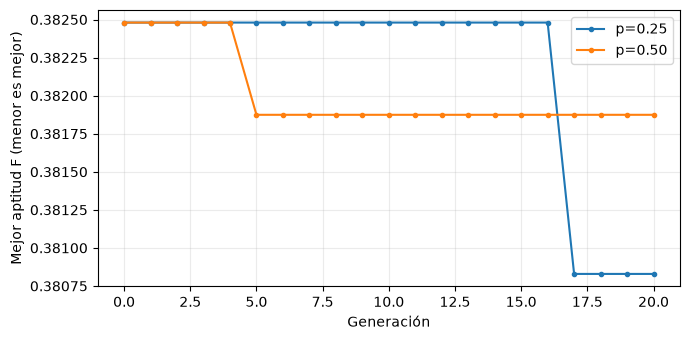

In [21]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Conserva la interpretación de tu equipo en una celda: identifica el parámetro cambiado; compara el mejor $F$, el agua potable y la factibilidad; explica una meseta o mejora; y delimita lo que puedes concluir de dos ejecuciones. Si los resultados coinciden, explica esa coincidencia con la misma validez. La variación no necesita ganar.

## 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [22]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


## 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

## Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.